# Finalist circuits on warm-start, cold-start S1 and cold-start S2

Follow-up to the screening notebook (1 seed, random split). Here the **finalist circuits** are trained and tested on all three settings with several seeds:

| Setting | What the test pairs look like |
|---|---|
| **Warm** (random split) | Both drugs were seen in training |
| **Cold S1** | Exactly one drug of the pair is new (never seen in training) |
| **Cold S2** | Both drugs are new, the hardest case |

Same pipeline, folds and GCN encoder as before; only the decoder differs. Each quantum finalist is compared with (a) a **parameter-matched MLP** and (b) the base circuit.
The two extra "(no ent)" variants remove all CNOTs while keeping the same multi-qubit readout. With a multi-qubit readout the no-entanglement test is **fair**: the circuit can use all 8 inputs even without entanglement (with a single measured qubit it could not).

**Runtime (rough estimate, not measured):** about 2 to 2.5 min per quantum run on a Colab CPU. With 5 quantum finalists, 2 regimes (warm and cold are trained separately) and 3 seeds, expect roughly 1 to 1.5 hours. Use `SEEDS = [0]` for a first look.

## 0. Setup

In [ ]:
# Colab / fresh environment. Safe to re-run; skip if everything is already installed.
# NOTE: do not `pip install PyTDC` normally. It pins an old scikit-learn that has no wheel for new Python versions,
# so pip tries to compile it from source and fails. Install PyTDC with --no-deps and add only what it really needs.
%pip install -q rdkit qiskit
%pip install -q --no-deps PyTDC
%pip install -q tqdm fuzzywuzzy huggingface_hub tiledbsoma cellxgene-census gget "setuptools<81"
# (torch, scikit-learn, pandas, scipy, matplotlib are already in Colab; locally: pip install torch scikit-learn pandas scipy matplotlib)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pytdc 1.1.15 requires dataclasses<1.0,>=0.6, which is not installed.
pytdc 1.1.15 requires evaluate==0.4.2, which is not installed.
pytdc 1.1.15 requires accelerate==0.33.0, but you have accelerate 1.15.0 which is incompatible.
pytdc 1.1.15 requires cellxgene-census==1.15.0, but you have cellxgene-census 1.18.0 which is incompatible.
pytdc 1.1.15 requires datasets<2.20.0, but you have datasets 4.8.5 which is incompatible.
pytdc 1.1.15 requires huggingface_hub<1.0,>=0.20.3, but you have huggingface-hub 1.33.0 which is incompatible.
pytdc 1.1.15 requires numpy<2.0.0,>=1.26.4, but you have numpy 2.4.6 which is incompatible.
pytdc 1.1.15 requires rdkit<2024.3.1,>=2023.9.5, but you have

## 1. Config  (the only cell you need to edit)

In [ ]:
DATA_SOURCE = "tdc"        # "tdc" | "csv" | "synthetic" (synthetic = pipeline smoke test only, meaningless results)
CSV_PATH    = "drugbank_ddi.csv"

N_TOTAL  = 20000
D_LIST   = [8]
SEEDS    = [0, 1, 2]       # 5 seeds for the final numbers: [0, 1, 2, 3, 4]
REGIMES  = ["random", "cold"]   # random -> warm; cold -> S1 and S2 (trained once on old-old pairs, tested on both)
EPOCHS   = 200
LR       = 1e-2
Q_LR     = 0.05
MATCHED_MLP = True

# Finalists (from the screening run: best validation AUPR, plus the base circuit and the no-entanglement counterparts)
RUN_ONLY = ["base: RYRZ / ring / Z0",
            "readout: all Z",
            "readout: all Z + ZZ",
            "readout: all Z + ZZ (no ent)",
            "entangle: none"]
OUT_DIR  = "results_finalists"
ART_DIR  = "artifacts"

## 2. Imports and data loading

In [ ]:
import os, time, math, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn
from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
RDLogger.DisableLog("rdApp.*"); warnings.filterwarnings("ignore")
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(ART_DIR, exist_ok=True)
torch.set_num_threads(max(1, os.cpu_count() or 1))
print("torch", torch.__version__, "| cpus", os.cpu_count())


def make_synthetic(n_drugs=400):
    # SYNTHETIC stand-in for smoke-testing the code. NOT DrugBank. Results on it mean nothing.
    rng = np.random.default_rng(0)
    frag = ["C","CC","C(=O)","N","O","c1ccccc1","C(F)","C(Cl)","S","C#N","C(=O)O","N(C)C","C1CC1","c1ccncc1"]
    smiles, seen = [], set()
    while len(smiles) < n_drugs:
        m = Chem.MolFromSmiles("".join(rng.choice(frag, size=rng.integers(3, 9))))
        if m is not None:
            s = Chem.MolToSmiles(m)
            if s not in seen: seen.add(s); smiles.append(s)
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    fp = np.stack([gen.GetFingerprintAsNumPy(Chem.MolFromSmiles(s)) for s in smiles]).astype(np.float32)
    z = fp @ rng.normal(size=(2048, 4)); z = (z - z.mean(0)) / (z.std(0) + 1e-6)
    score = z @ z.T + 0.5 * rng.normal(size=(n_drugs, n_drugs))
    iu = np.triu_indices(n_drugs, 1); sel = score[iu] > np.quantile(score[iu], 0.93)
    rows = [(f"SYN{a:04d}", smiles[a], f"SYN{b:04d}", smiles[b]) for a, b in zip(iu[0][sel], iu[1][sel])]
    return pd.DataFrame(rows, columns=["Drug1_ID", "Drug1", "Drug2_ID", "Drug2"])


def load_ddi_table():
    if DATA_SOURCE == "synthetic":
        print("!" * 70, "\nSYNTHETIC DATA: pipeline smoke test only, NOT DrugBank, NOT results\n" + "!" * 70)
        df = make_synthetic()
    elif DATA_SOURCE == "csv":
        df = pd.read_csv(CSV_PATH)
    else:
        from tdc.multi_pred import DDI
        df = DDI(name="DrugBank").get_data()
        df.to_csv("drugbank_ddi.csv", index=False)      # cache a local copy (do NOT commit this file: DrugBank licence)
    need = ["Drug1_ID", "Drug1", "Drug2_ID", "Drug2"]
    missing = [c for c in need if c not in df.columns]
    assert not missing, f"missing columns {missing}; got {list(df.columns)}"
    return df[need].copy()


df = load_ddi_table()
print("rows in table:", len(df)); df.head(3)

torch 2.14.1+cpu | cpus 2


Downloading...
100%|██████████| 44.4M/44.4M [00:01<00:00, 31.4MiB/s]
Loading...
Done!


rows in table: 191808


,Drug1_ID,Drug1,Drug2_ID,Drug2
0,DB04571,CC1=CC2=CC3=C(OC(=O)C=C3C)C(C)=C2O1,DB00460,COC(=O)CCC1=C2NC(\C=C3/N=C(/C=C4\N\C(=C/C5=N/C...
1,DB00855,NCC(=O)CCC(O)=O,DB00460,COC(=O)CCC1=C2NC(\C=C3/N=C(/C=C4\N\C(=C/C5=N/C...
2,DB09536,O=[Ti]=O,DB00460,COC(=O)CCC1=C2NC(\C=C3/N=C(/C=C4\N\C(=C/C5=N/C...


## 3. Data pipeline: drugs, positives, negatives, folds, features
Pairs are treated as unordered (`i < j`). Cold-start: 20% of drugs are held out as "new"; train/val use old-old pairs only;
**S1** = exactly one new drug, **S2** = both new.

In [ ]:
def build_drugs_and_positives(df):
    smi = {}
    for a, s in zip(df.Drug1_ID, df.Drug1): smi.setdefault(a, s)
    for a, s in zip(df.Drug2_ID, df.Drug2): smi.setdefault(a, s)
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    ids, fps = [], []
    for k, s in smi.items():
        m = Chem.MolFromSmiles(s) if isinstance(s, str) else None
        if m is None: continue                       # drop drugs RDKit cannot parse
        ids.append(k); fps.append(gen.GetFingerprintAsNumPy(m).astype(np.uint8))
    index = {k: i for i, k in enumerate(ids)}
    pairs = set()
    for a, b in zip(df.Drug1_ID, df.Drug2_ID):
        if a in index and b in index and a != b:
            i, j = index[a], index[b]; pairs.add((min(i, j), max(i, j)))
    return ids, np.stack(fps), np.array(sorted(pairs), dtype=np.int64)


def sample_negatives(pos, n_drugs, n_neg, rng):
    known = set((pos[:, 0] * n_drugs + pos[:, 1]).tolist()); out = set()
    while len(out) < n_neg:
        i = rng.integers(0, n_drugs, size=2 * (n_neg - len(out)) + 16); j = rng.integers(0, n_drugs, size=i.shape)
        for a, b in zip(i.tolist(), j.tolist()):
            if a == b: continue
            a, b = (a, b) if a < b else (b, a); key = a * n_drugs + b
            if key in known or key in out: continue
            out.add(key)
            if len(out) == n_neg: break
    out = np.array(sorted(out), dtype=np.int64)
    return np.stack([out // n_drugs, out % n_drugs], 1)


def build_labeled_pairs(pos, n_drugs, rng, n_total=None):
    if n_total:
        pos_used = pos[np.sort(rng.choice(len(pos), size=n_total // 2, replace=False))]
    else:
        pos_used = pos
    neg = sample_negatives(pos, n_drugs, len(pos_used), rng)       # drawn against ALL known positives
    pairs = np.concatenate([pos_used, neg])
    y = np.concatenate([np.ones(len(pos_used)), np.zeros(len(neg))]).astype(np.float32)
    perm = rng.permutation(len(pairs))
    return pairs[perm], y[perm]


def random_split(n_pairs, rng, frac=(0.8, 0.1, 0.1)):
    perm = rng.permutation(n_pairs); a, b = int(frac[0] * n_pairs), int((frac[0] + frac[1]) * n_pairs)
    return {"train": perm[:a], "val": perm[a:b], "test": perm[b:]}


def cold_start_split(pairs, n_drugs, rng, new_frac=0.2, val_frac=0.1):
    new = np.zeros(n_drugs, bool); new[rng.choice(n_drugs, size=int(new_frac * n_drugs), replace=False)] = True
    n_new = new[pairs[:, 0]].astype(int) + new[pairs[:, 1]].astype(int)
    old_old = rng.permutation(np.where(n_new == 0)[0]); nv = int(val_frac * len(old_old))
    return {"train": old_old[nv:], "val": old_old[:nv],
            "test_s1": np.where(n_new == 1)[0], "test_s2": np.where(n_new == 2)[0]}, new


def check_split(pairs, y, split, n_drugs, new=None):
    all_idx = np.concatenate([split[k] for k in split])
    assert len(all_idx) == len(set(all_idx.tolist())), "a pair appears in more than one split"
    keys = pairs[:, 0] * n_drugs + pairs[:, 1]
    assert len(set(keys.tolist())) == len(keys), "duplicate pairs (a positive is also a negative?)"
    if new is not None:
        for k in ("train", "val"):
            p = pairs[split[k]]; assert not (new[p[:, 0]] | new[p[:, 1]]).any(), f"new drug leaked into {k}"
        p1, p2 = pairs[split["test_s1"]], pairs[split["test_s2"]]
        assert ((new[p1[:, 0]].astype(int) + new[p1[:, 1]].astype(int)) == 1).all()
        assert new[p2[:, 0]].all() and new[p2[:, 1]].all()


def pca_features(fps, train_pairs, d, seed=0):
    # PCA fit ONLY on drugs seen in training pairs, then standardise (train drugs only)
    tr = np.unique(train_pairs.ravel())
    pca = PCA(n_components=d, random_state=seed).fit(fps[tr].astype(np.float32))
    z = pca.transform(fps.astype(np.float32)); sc = StandardScaler().fit(z[tr])
    return sc.transform(z).astype(np.float32), float(pca.explained_variance_ratio_.sum())


def pair_vectors(x, pairs):
    a, b = x[pairs[:, 0]], x[pairs[:, 1]]
    return np.concatenate([a + b, a * b], axis=1)          # symmetric: drug order does not matter


ids, fps, pos = build_drugs_and_positives(df)
n = len(ids)
print(f"drugs = {n} | unique unordered positive pairs = {len(pos)} | density = {len(pos) / (n * (n - 1) / 2):.3f}")

drugs = 1705 | unique unordered positive pairs = 191392 | density = 0.132


## 4. Classical baseline: GCN + MLP
GCN encoder, `Linear -> d`, then an MLP decoder (d → 16 → 1).
Each epoch a random 70% of training positives form the message-passing graph and the other 30% (plus an equal number of training negatives) are the targets, so no supervised edge is visible to the encoder.
Evaluation graph = all training positives. Best epoch by validation AUPR; F1 threshold chosen on validation only.

In [ ]:
def best_f1_threshold(y, s):
    ts = np.unique(np.quantile(s, np.linspace(0.01, 0.99, 99)))
    return float(ts[int(np.argmax([f1_score(y, s >= t, zero_division=0) for t in ts]))])

def metrics(y, s, thr):
    return {"AUROC": roc_auc_score(y, s), "AUPR": average_precision_score(y, s), "F1": f1_score(y, s >= thr, zero_division=0)}

def norm_adj(n, edges, device="cpu"):
    A = torch.zeros(n, n, device=device)
    if len(edges):
        e = torch.as_tensor(edges, device=device); A[e[:, 0], e[:, 1]] = 1.0; A[e[:, 1], e[:, 0]] = 1.0
    A = A + torch.eye(n, device=device); dinv = A.sum(1).pow(-0.5)
    return dinv[:, None] * A * dinv[None, :]

class GCNEncoder(nn.Module):
    def __init__(self, in_dim, hid, out):
        super().__init__(); self.l1, self.l2 = nn.Linear(in_dim, hid), nn.Linear(hid, out)
    def forward(self, x, A):
        return A @ self.l2(torch.relu(A @ self.l1(x)))

class MLPCore(nn.Module):
    # classical decoder: d values -> hidden -> logit
    def __init__(self, d, hidden):
        super().__init__(); self.net = nn.Sequential(nn.Linear(d, hidden), nn.ReLU(), nn.Linear(hidden, 1))
    def forward(self, z): return self.net(z).squeeze(-1)


## 5. Configurable quantum decoder
The decoder takes the d = 8 compressed values (via tanh), loads them as `RY` angles on 8 qubits, applies L variational layers, and reads out expectation values:

`logit = Linear( [ ⟨Z_k⟩ for the measured qubits (+ ⟨Z_k Z_k+1⟩ correlators) ] )`

**Entanglement patterns** (CNOT gates per layer): `none` · `linear` (0→1, …, 6→7) · `ring` (linear + 7→0) · `brick` (even layers pair (0,1),(2,3)…; odd layers pair (1,2),(3,4)…,(7,0)) · `full` (all 28 pairs).

**Trainable parameters** = rotation angles (`n × layers × {1, 2, 3}`) + readout layer (`#features + 1`).
The circuit is simulated exactly as a differentiable statevector in PyTorch; section 6 verifies **every** option against Qiskit.

In [ ]:
import math

def cnot_pairs(topology, n, layer):
    if topology == "none":   return []
    if topology == "linear": return [(i, i + 1) for i in range(n - 1)]
    if topology == "ring":   return [(i, (i + 1) % n) for i in range(n)]
    if topology == "brick":  return [(i, (i + 1) % n) for i in range(layer % 2, n, 2)]
    if topology == "full":   return [(i, j) for i in range(n) for j in range(i + 1, n)]
    raise ValueError(topology)

def perm_from_pairs(n, pairs):
    # composite permutation for a sequence of CNOT(c,t) on a flat statevector (qubit 0 = most significant bit)
    idx = torch.arange(2 ** n); perm = idx.clone()
    for c, t in pairs:
        p = torch.where(((idx >> (n - 1 - c)) & 1) == 1, idx ^ (1 << (n - 1 - t)), idx)
        perm = perm[p]
    return perm

def readout_specs(n, readout):
    # each spec is a tuple of qubits whose Pauli-Z product is measured
    z = [(q,) for q in range(n)]
    if readout == "z0":      return [(0,)]
    if readout == "zall":    return z
    if readout == "zall_zz": return z + [(q, (q + 1) % n) for q in range(n)]
    raise ValueError(readout)

def readout_signs(n, specs):
    idx = torch.arange(2 ** n); cols = []
    for sp in specs:
        s = torch.ones(2 ** n)
        for q in sp: s = s * (1 - 2 * ((idx >> (n - 1 - q)) & 1)).float()
        cols.append(s)
    return torch.stack(cols, 1)

def ry_mat(theta):
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2).to(torch.cfloat)

def rz_mat(phi):
    c, s = torch.cos(phi / 2), torch.sin(phi / 2); z = torch.zeros_like(c)
    d0, d1 = torch.complex(c, -s), torch.complex(c, s)
    return torch.stack([torch.stack([d0, z.to(torch.cfloat)], -1), torch.stack([z.to(torch.cfloat), d1], -1)], -2)

class VQCore(nn.Module):
    K = {"ry": 1, "ryrz": 2, "rot": 3}                     # rotation parameters per qubit per layer
    def __init__(self, n, ansatz="ryrz", ent="ring", readout="z0", layers=2, reupload=False):
        super().__init__()
        self.n, self.L, self.ansatz, self.ent, self.reupload = n, layers, ansatz, ent, reupload
        self.w = nn.Parameter(torch.randn(layers, n, self.K[ansatz]))
        self.register_buffer("perms", torch.stack([perm_from_pairs(n, cnot_pairs(ent, n, l)) for l in range(layers)]))
        self.register_buffer("S", readout_signs(n, readout_specs(n, readout)))
        m = self.S.shape[1]
        self.out = nn.Linear(m, 1)
        with torch.no_grad(): self.out.weight.fill_(3.0 / m); self.out.bias.zero_()

    def _U(self, l):                                       # (n,2,2) one gate per qubit
        w = self.w[l]
        if self.ansatz == "ry":   return ry_mat(w[:, 0])
        if self.ansatz == "ryrz": return rz_mat(w[:, 1]) @ ry_mat(w[:, 0])               # RY first, then RZ
        return rz_mat(w[:, 2]) @ ry_mat(w[:, 1]) @ rz_mat(w[:, 0])                         # RZ, RY, RZ

    def probs(self, angles):
        B, n = angles.shape
        c, s = torch.cos(angles / 2), torch.sin(angles / 2)
        st = torch.ones(B, 1, dtype=torch.cfloat)
        for i in range(n):                                 # RY(angle_i)|0> on every qubit
            q = torch.stack([c[:, i], s[:, i]], 1).to(torch.cfloat)
            st = (st[:, :, None] * q[:, None, :]).reshape(B, -1)
        for l in range(self.L):
            if self.reupload and l > 0:                    # data re-uploading: encode the inputs again
                R = ry_mat(angles)                         # (B,n,2,2)
                for i in range(n):
                    st = torch.einsum("bij,bajc->baic", R[:, i], st.reshape(B, 2 ** i, 2, 2 ** (n - i - 1))).reshape(B, -1)
            U = self._U(l)
            for i in range(n):
                st = torch.einsum("ij,bajc->baic", U[i], st.reshape(B, 2 ** i, 2, 2 ** (n - i - 1))).reshape(B, -1)
            if self.ent != "none": st = st[:, self.perms[l]]
        return st.real ** 2 + st.imag ** 2

    def features(self, angles): return self.probs(angles) @ self.S          # measured expectation values
    def forward(self, z): return self.out(self.features(math.pi * z)).squeeze(-1)

def n_params(m): return sum(p.numel() for p in m.parameters())
def mlp_hidden_for_params(d, target): return max(1, round((target - 1) / (d + 2)))   # params = h*(d+2)+1

## 6. Verify every circuit option against Qiskit

In [ ]:
def qiskit_crosscheck(n=5, n_samples=4, seed=0):
    try:
        from qiskit import QuantumCircuit
        from qiskit.quantum_info import Statevector, SparsePauliOp
    except Exception as e:
        print("Qiskit not available, skipping cross-check:", e); return
    configs = [dict(ansatz=a, ent=e, readout="zall_zz", layers=3, reupload=r)
               for a in ("ry", "ryrz", "rot") for e in ("none", "linear", "ring", "brick", "full") for r in (False, True)][::2]
    configs += [dict(ansatz="rot", ent="brick", readout="z0", layers=2, reupload=True)]
    worst = 0.0
    for cfg in configs:
        torch.manual_seed(seed); core = VQCore(n, **cfg)
        ang = math.pi * (torch.rand(n_samples, n) * 2 - 1)
        with torch.no_grad(): mine = core.features(ang).numpy()
        specs = readout_specs(n, cfg["readout"]); ref = np.zeros_like(mine)
        for k in range(n_samples):
            qc = QuantumCircuit(n)
            for i in range(n): qc.ry(float(ang[k, i]), i)
            for l in range(cfg["layers"]):
                if cfg["reupload"] and l > 0:
                    for i in range(n): qc.ry(float(ang[k, i]), i)
                for i in range(n):
                    w = core.w[l, i].detach().tolist()
                    if cfg["ansatz"] == "ry":    qc.ry(w[0], i)
                    elif cfg["ansatz"] == "ryrz": qc.ry(w[0], i); qc.rz(w[1], i)
                    else:                         qc.rz(w[0], i); qc.ry(w[1], i); qc.rz(w[2], i)
                for c_, t_ in cnot_pairs(cfg["ent"], n, l): qc.cx(c_, t_)
            sv = Statevector(qc)
            for j, sp in enumerate(specs):
                lab = ["I"] * n
                for q in sp: lab[n - 1 - q] = "Z"                    # Qiskit: rightmost character = qubit 0
                ref[k, j] = sv.expectation_value(SparsePauliOp("".join(lab))).real
        worst = max(worst, float(np.abs(mine - ref).max()))
    print(f"checked {len(configs)} circuit configurations; max |torch - qiskit| = {worst:.2e}", "OK" if worst < 1e-4 else "MISMATCH")
    assert worst < 1e-4
qiskit_crosscheck()

checked 16 circuit configurations; max |torch - qiskit| = 4.77e-07 OK


## 7. Variants
The screening variants plus two multi-qubit-readout circuits **without** entanglement (the fair counterparts for criterion (b)). Only the names in `RUN_ONLY` are trained.

In [ ]:
BASE = "base: RYRZ / ring / Z0"
VARIANTS = {
    BASE:                          dict(ansatz="ryrz", ent="ring",   readout="z0",      layers=2, reupload=False),
    "ansatz: RY only":             dict(ansatz="ry",   ent="ring",   readout="z0",      layers=2, reupload=False),
    "ansatz: general Rot":         dict(ansatz="rot",  ent="ring",   readout="z0",      layers=2, reupload=False),
    "entangle: none":              dict(ansatz="ryrz", ent="none",   readout="z0",      layers=2, reupload=False),
    "entangle: linear":            dict(ansatz="ryrz", ent="linear", readout="z0",      layers=2, reupload=False),
    "entangle: brick":             dict(ansatz="ryrz", ent="brick",  readout="z0",      layers=2, reupload=False),
    "entangle: full":              dict(ansatz="ryrz", ent="full",   readout="z0",      layers=2, reupload=False),
    "readout: all Z":              dict(ansatz="ryrz", ent="ring",   readout="zall",    layers=2, reupload=False),
    "readout: all Z + ZZ":         dict(ansatz="ryrz", ent="ring",   readout="zall_zz", layers=2, reupload=False),
    "depth: 4 layers":             dict(ansatz="ryrz", ent="ring",   readout="z0",      layers=4, reupload=False),
    "readout: all Z (no ent)":     dict(ansatz="ryrz", ent="none",   readout="zall",    layers=2, reupload=False),
    "readout: all Z + ZZ (no ent)": dict(ansatz="ryrz", ent="none",   readout="zall_zz", layers=2, reupload=False),
    "data re-uploading":           dict(ansatz="ryrz", ent="ring",   readout="z0",      layers=2, reupload=True),
}
D0 = D_LIST[0]
active = {k: v for k, v in VARIANTS.items() if (RUN_ONLY is None or k in RUN_ONLY or k == BASE)}
tbl = pd.DataFrame([{"variant": k, "decoder_params": n_params(VQCore(D0, **v)), **v} for k, v in active.items()]).set_index("variant")
tbl["matched_mlp_hidden"] = [mlp_hidden_for_params(D0, p) for p in tbl.decoder_params]
display(tbl)

,decoder_params,ansatz,ent,readout,layers,reupload,matched_mlp_hidden
variant,,,,,,,
base: RYRZ / ring / Z0,34,ryrz,ring,z0,2,False,3
entangle: none,34,ryrz,none,z0,2,False,3
readout: all Z,41,ryrz,ring,zall,2,False,4
readout: all Z + ZZ,49,ryrz,ring,zall_zz,2,False,5
readout: all Z + ZZ (no ent),49,ryrz,none,zall_zz,2,False,5


## 8. Model wrapper and training
Identical to the core notebook (same GCN, same compression layer, same 70/30 message-passing split, best epoch by validation AUPR), except the decoder is built from a spec and the function also returns the best **validation** AUPR, which is what you should use to pick variants.

In [ ]:
def build_core(spec, d):
    if spec["kind"] == "mlp": return MLPCore(d, spec["hidden"])
    return VQCore(d, spec["ansatz"], spec["ent"], spec["readout"], spec["layers"], spec["reupload"])

class PairHead(nn.Module):
    # pair -> [hi+hj, hi*hj] -> Linear -> d values -> tanh -> decoder core
    def __init__(self, emb, d, core):
        super().__init__(); self.compress = nn.Linear(2 * emb, d); self.core = core
    def forward(self, h, pairs):
        a, b = h[pairs[:, 0]], h[pairs[:, 1]]
        return self.core(torch.tanh(self.compress(torch.cat([a + b, a * b], 1))))

class GCNModel(nn.Module):
    def __init__(self, in_dim, spec, d, hid=64, emb=32):
        super().__init__(); self.enc = GCNEncoder(in_dim, hid, emb); self.head = PairHead(emb, d, build_core(spec, d))

def run_gcn(x, n_nodes, pairs, y, split, d, spec, seed=0, epochs=200, lr=1e-2, mp_frac=0.7):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)       # same seed -> same encoder init and batches for every decoder
    x_t = torch.as_tensor(x); tr = split["train"]
    tr_pos, tr_neg = tr[y[tr] == 1], tr[y[tr] == 0]
    model = GCNModel(x.shape[1], spec, d)
    is_q = spec["kind"] == "qnn"
    groups = [{"params": [p for nme, p in model.named_parameters() if not nme.startswith("head.core")], "lr": lr},
              {"params": list(model.head.core.parameters()), "lr": Q_LR if is_q else lr}]
    opt = torch.optim.Adam(groups, weight_decay=5e-4)
    A_eval = norm_adj(n_nodes, pairs[tr_pos]); P = lambda idx: torch.as_tensor(pairs[idx])

    def score(idx, chunk=4096):
        model.eval(); out = []
        with torch.no_grad():
            h = model.enc(x_t, A_eval)
            for s in range(0, len(idx), chunk):
                out.append(torch.sigmoid(model.head(h, P(idx[s:s + chunk]))).numpy())
        return np.concatenate(out)

    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        perm = rng.permutation(tr_pos); k = int(mp_frac * len(perm)); mp, sup_pos = perm[:k], perm[k:]
        sup_neg = rng.choice(tr_neg, size=len(sup_pos), replace=False)
        A = norm_adj(n_nodes, pairs[mp]); sup = np.concatenate([sup_pos, sup_neg])
        loss = nn.functional.binary_cross_entropy_with_logits(model.head(model.enc(x_t, A), P(sup)), torch.as_tensor(y[sup]))
        opt.zero_grad(); loss.backward(); opt.step()
        if ep % 5 == 4:
            v = average_precision_score(y[split["val"]], score(split["val"]))
            if v > best: best, best_state = v, {k_: t.clone() for k_, t in model.state_dict().items()}
    model.load_state_dict(best_state)
    thr = best_f1_threshold(y[split["val"]], score(split["val"]))
    res = {k: metrics(y[split[k]], score(split[k]), thr) for k in split if k.startswith("test")}
    return res, n_params(model), n_params(model.head.core), float(best)

## 9. Run

In [ ]:
rows, MATCH = [], {}
t_all = time.time()
for seed in SEEDS:
    rng = np.random.default_rng(seed)
    pairs, y = build_labeled_pairs(pos, n, rng, N_TOTAL or None)
    regimes = {"random": (random_split(len(pairs), rng), None)}
    regimes["cold"] = cold_start_split(pairs, n, rng)
    art = dict(pairs=pairs, y=y, new_mask=regimes["cold"][1])
    for r, (sp, _) in regimes.items():
        for k, v in sp.items(): art[f"{r}_{k}"] = v
    for regime, (split, new) in regimes.items():
        check_split(pairs, y, split, n, new)
        x, evr = pca_features(fps, pairs[split["train"]], D0, seed); art[f"x_{regime}_d{D0}"] = x
        if regime not in REGIMES: continue
        print(f"[seed {seed}] {regime}: " + ", ".join(f"{k}={len(v)}" for k, v in split.items()))
        specs = {"GCN+MLP (h=16)": dict(kind="mlp", hidden=16)}
        for vname, cfg in active.items(): specs[vname] = dict(kind="qnn", **cfg)
        if MATCHED_MLP:
            for vname, cfg in active.items():
                h = mlp_hidden_for_params(D0, n_params(VQCore(D0, **cfg))); mname = f"MLP matched (h={h})"
                MATCH[vname] = mname; specs.setdefault(mname, dict(kind="mlp", hidden=h))
        for name, spec in specs.items():
            t0 = time.perf_counter()
            out, npar, hpar, vbest = run_gcn(x, n, pairs, y, split, D0, spec, seed, EPOCHS, LR)
            wall = time.perf_counter() - t0
            for tk, m in out.items():
                rows.append(dict(seed=seed, regime=regime, test=tk, d=D0, model=name, kind=spec["kind"], params=npar, head_params=hpar,
                                 val_AUPR=round(vbest, 4), wall_s=round(wall, 1), pos_rate=round(float(y[split[tk]].mean()), 3), n_test=len(split[tk]), **{k: round(float(v), 4) for k, v in m.items()}))
            print(f"   {name:<28} head_params={hpar:<4} {wall:6.1f}s  val AUPR={vbest:.3f}  " + "  ".join(f"{tk}: AUPR={m['AUPR']:.3f}" for tk, m in out.items()))
    np.savez_compressed(f"{ART_DIR}/pairs_seed{seed}.npz", **art)
res = pd.DataFrame(rows); os.makedirs(OUT_DIR, exist_ok=True); res.to_csv(f"{OUT_DIR}/metrics_long.csv", index=False)
print(f"\nDone in {(time.time() - t_all) / 60:.1f} min.")

[seed 0] random: train=16000, val=2000, test=2000
   GCN+MLP (h=16)               head_params=161    46.6s  val AUPR=0.901  test: AUPR=0.902
   base: RYRZ / ring / Z0       head_params=34    141.5s  val AUPR=0.902  test: AUPR=0.901
   entangle: none               head_params=34    151.9s  val AUPR=0.896  test: AUPR=0.890
   readout: all Z               head_params=41    156.9s  val AUPR=0.908  test: AUPR=0.909
   readout: all Z + ZZ          head_params=49    147.0s  val AUPR=0.909  test: AUPR=0.912
   readout: all Z + ZZ (no ent) head_params=49    134.4s  val AUPR=0.906  test: AUPR=0.909
   MLP matched (h=3)            head_params=31     11.9s  val AUPR=0.888  test: AUPR=0.886
   MLP matched (h=4)            head_params=41      9.7s  val AUPR=0.898  test: AUPR=0.898
   MLP matched (h=5)            head_params=51     12.1s  val AUPR=0.901  test: AUPR=0.901
[seed 0] cold: train=11506, val=1278, test_s1=6447, test_s2=769
   GCN+MLP (h=16)               head_params=161    11.8s  val AUPR=

## 10. Results by setting
`test` is the warm test set; `test_s1` and `test_s2` are the cold-start sets. **Chance level for AUROC is always 0.5. Chance level for AUPR equals the fraction of positives in that test set** (column `pos_rate`), which can differ from 0.5 on the cold-start sets, so lean on AUROC there.

In [ ]:
SETTING = {"test": "warm", "test_s1": "cold S1", "test_s2": "cold S2"}
res["setting"] = res.test.map(SETTING)
order_settings = [s for s in ["warm", "cold S1", "cold S2"] if s in set(res.setting)]
quantum = [m for m in VARIANTS if m in set(res.model)]

# 1) one table per setting, sorted by validation AUPR
for st in order_settings:
    g = res[res.setting == st]
    t = (g.groupby("model").agg(val_AUPR=("val_AUPR", "mean"), AUPR=("AUPR", "mean"), AUPR_std=("AUPR", "std"),
                                AUROC=("AUROC", "mean"), AUROC_std=("AUROC", "std"), decoder_params=("head_params", "first"),
                                test_pos_rate=("pos_rate", "mean"), n_test=("n_test", "mean"), wall_s=("wall_s", "mean"))
           .sort_values("val_AUPR", ascending=False).round(4))
    print(f"--- {st}  ({len(SEEDS)} seed(s))"); display(t); t.to_csv(f"{OUT_DIR}/summary_{st.replace(' ', '_')}.csv")

--- warm  (3 seed(s))


,val_AUPR,AUPR,AUPR_std,AUROC,AUROC_std,decoder_params,test_pos_rate,n_test,wall_s
model,,,,,,,,,
readout: all Z + ZZ,0.9084,0.9105,0.0017,0.9134,0.0025,49,0.4943,2000.0,144.8000
readout: all Z,0.9060,0.9102,0.0022,0.9132,0.0036,41,0.4943,2000.0,148.3000
readout: all Z + ZZ (no ent),0.9035,0.9069,0.0016,0.9123,0.0019,49,0.4943,2000.0,133.4000
base: RYRZ / ring / Z0,0.8995,0.9033,0.0025,0.9098,0.0052,34,0.4943,2000.0,144.8000
GCN+MLP (h=16),0.8982,0.9004,0.0015,0.9072,0.0031,161,0.4943,2000.0,23.8000
MLP matched (h=5),0.8979,0.9000,0.0040,0.9062,0.0033,51,0.4943,2000.0,12.0000
MLP matched (h=4),0.8965,0.8974,0.0008,0.9051,0.0038,41,0.4943,2000.0,11.2000
entangle: none,0.8900,0.8904,0.0041,0.9026,0.0029,34,0.4943,2000.0,146.1667
MLP matched (h=3),0.8861,0.8894,0.0083,0.9024,0.0078,31,0.4943,2000.0,11.9000


--- cold S1  (3 seed(s))


,val_AUPR,AUPR,AUPR_std,AUROC,AUROC_std,decoder_params,test_pos_rate,n_test,wall_s
model,,,,,,,,,
readout: all Z + ZZ,0.9068,0.6744,0.0031,0.6850,0.0048,49,0.5013,6431.0,108.8000
base: RYRZ / ring / Z0,0.9065,0.6714,0.0079,0.6800,0.0188,34,0.5013,6431.0,108.1667
readout: all Z + ZZ (no ent),0.9061,0.6665,0.0122,0.6753,0.0306,49,0.5013,6431.0,108.1000
readout: all Z,0.9060,0.6793,0.0032,0.6887,0.0096,41,0.5013,6431.0,106.0000
GCN+MLP (h=16),0.8955,0.6995,0.0118,0.7117,0.0024,161,0.5013,6431.0,11.6333
MLP matched (h=4),0.8913,0.6925,0.0110,0.7057,0.0242,41,0.5013,6431.0,10.8667
MLP matched (h=5),0.8905,0.7117,0.0139,0.7294,0.0193,51,0.5013,6431.0,12.2000
entangle: none,0.8884,0.6881,0.0141,0.6987,0.0139,34,0.5013,6431.0,105.9333
MLP matched (h=3),0.8844,0.6938,0.0254,0.7064,0.0262,31,0.5013,6431.0,11.6333


--- cold S2  (3 seed(s))


,val_AUPR,AUPR,AUPR_std,AUROC,AUROC_std,decoder_params,test_pos_rate,n_test,wall_s
model,,,,,,,,,
readout: all Z + ZZ,0.9068,0.5712,0.0643,0.5522,0.0445,49,0.517,815.3333,108.8000
base: RYRZ / ring / Z0,0.9065,0.5910,0.0556,0.5882,0.0159,34,0.517,815.3333,108.1667
readout: all Z + ZZ (no ent),0.9061,0.5781,0.0477,0.5544,0.0118,49,0.517,815.3333,108.1000
readout: all Z,0.9060,0.5733,0.0848,0.5603,0.0605,41,0.517,815.3333,106.0000
GCN+MLP (h=16),0.8955,0.5959,0.0692,0.5738,0.0250,161,0.517,815.3333,11.6333
MLP matched (h=4),0.8913,0.5949,0.0579,0.5841,0.0332,41,0.517,815.3333,10.8667
MLP matched (h=5),0.8905,0.6114,0.0803,0.5960,0.0467,51,0.517,815.3333,12.2000
entangle: none,0.8884,0.5715,0.0666,0.5427,0.0403,34,0.517,815.3333,105.9333
MLP matched (h=3),0.8844,0.5809,0.0841,0.5626,0.0399,31,0.517,815.3333,11.6333


In [ ]:
# 2) the three settings side by side (mean AUROC and AUPR)
wide = res.pivot_table(index="model", columns="setting", values=["AUROC", "AUPR"], aggfunc="mean")[[(m, s) for m in ["AUROC", "AUPR"] for s in order_settings]].round(3)
wide = wide.reindex([m for m in quantum + sorted([m for m in res.model.unique() if m not in quantum])])
print("Mean over seeds"); display(wide); wide.to_csv(f"{OUT_DIR}/side_by_side.csv")

Mean over seeds


AUROC                   AUPR                
setting                        warm cold S1 cold S2   warm cold S1 cold S2
model                                                                     
base: RYRZ / ring / Z0        0.910   0.680   0.588  0.903   0.671   0.591
entangle: none                0.903   0.699   0.543  0.890   0.688   0.572
readout: all Z                0.913   0.689   0.560  0.910   0.679   0.573
readout: all Z + ZZ           0.913   0.685   0.552  0.910   0.674   0.571
readout: all Z + ZZ (no ent)  0.912   0.675   0.554  0.907   0.666   0.578
GCN+MLP (h=16)                0.907   0.712   0.574  0.900   0.700   0.596
MLP matched (h=3)             0.902   0.706   0.563  0.889   0.694   0.581
MLP matched (h=4)             0.905   0.706   0.584  0.897   0.693   0.595
MLP matched (h=5)             0.906   0.729   0.596  0.900   0.712   0.611

In [ ]:
from scipy import stats
def paired_delta(ref_of, label, metric="AUPR"):
    piv = res.pivot_table(index=["setting", "seed"], columns="model", values=metric)
    out = []
    for st, g in piv.groupby(level="setting"):
        g = g.droplevel("setting")
        for v in quantum:
            ref = ref_of(v)
            if ref is None or ref == v or v not in g.columns or ref not in g.columns: continue
            dlt = (g[v] - g[ref]).dropna().values
            if len(dlt) >= 2:
                m_, se = dlt.mean(), dlt.std(ddof=1) / np.sqrt(len(dlt)); h = stats.t.ppf(0.975, len(dlt) - 1) * se
                lo, hi = m_ - h, m_ + h; ci = f"[{lo:.3f}, {hi:.3f}]"; excl = bool(lo > 0 or hi < 0)
            else:
                m_, ci, excl = dlt.mean(), "n/a (1 seed)", None
            out.append(dict(setting=st, variant=v, vs=ref, n_seeds=len(dlt), delta=round(m_, 4), CI95=ci, CI_excludes_0=excl, **{"delta>=0.01": bool(m_ >= 0.01)}))
    d = pd.DataFrame(out); print(label); display(d); return d

MATCH_REF = lambda v: MATCH.get(v)
dA = paired_delta(MATCH_REF, "A. Quantum variant minus parameter-matched MLP (AUPR). Criterion (a): helps only if delta >= 0.01 AND the CI excludes 0")
dA_roc = paired_delta(MATCH_REF, "A'. Same, in AUROC (safer for the cold-start sets)", metric="AUROC")
dB = paired_delta(lambda v: BASE if v != BASE else None, "B. Variant minus the base circuit (AUPR)")
dA.to_csv(f"{OUT_DIR}/delta_vs_matched_mlp.csv", index=False); dA_roc.to_csv(f"{OUT_DIR}/delta_vs_matched_mlp_auroc.csv", index=False); dB.to_csv(f"{OUT_DIR}/delta_vs_base.csv", index=False)

A. Quantum variant minus parameter-matched MLP (AUPR). Criterion (a): helps only if delta >= 0.01 AND the CI excludes 0


,setting,variant,vs,n_seeds,delta,CI95,CI_excludes_0,delta>=0.01
0,cold S1,base: RYRZ / ring / Z0,MLP matched (h=3),3,-0.0224,"[-0.073, 0.029]",False,False
1,cold S1,entangle: none,MLP matched (h=3),3,-0.0057,"[-0.034, 0.022]",False,False
2,cold S1,readout: all Z,MLP matched (h=4),3,-0.0133,"[-0.036, 0.009]",False,False
3,cold S1,readout: all Z + ZZ,MLP matched (h=5),3,-0.0373,"[-0.065, -0.009]",True,False
4,cold S1,readout: all Z + ZZ (no ent),MLP matched (h=5),3,-0.0452,"[-0.095, 0.005]",False,False
5,cold S2,base: RYRZ / ring / Z0,MLP matched (h=3),3,0.0100,"[-0.068, 0.088]",False,True
6,cold S2,entangle: none,MLP matched (h=3),3,-0.0094,"[-0.087, 0.068]",False,False
7,cold S2,readout: all Z,MLP matched (h=4),3,-0.0216,"[-0.145, 0.102]",False,False
8,cold S2,readout: all Z + ZZ,MLP matched (h=5),3,-0.0402,"[-0.152, 0.071]",False,False
9,cold S2,readout: all Z + ZZ (no ent),MLP matched (h=5),3,-0.0333,"[-0.134, 0.067]",False,False


A'. Same, in AUROC (safer for the cold-start sets)


,setting,variant,vs,n_seeds,delta,CI95,CI_excludes_0,delta>=0.01
0,cold S1,base: RYRZ / ring / Z0,MLP matched (h=3),3,-0.0264,"[-0.086, 0.033]",False,False
1,cold S1,entangle: none,MLP matched (h=3),3,-0.0076,"[-0.038, 0.023]",False,False
2,cold S1,readout: all Z,MLP matched (h=4),3,-0.0170,"[-0.077, 0.044]",False,False
3,cold S1,readout: all Z + ZZ,MLP matched (h=5),3,-0.0444,"[-0.083, -0.005]",True,False
4,cold S1,readout: all Z + ZZ (no ent),MLP matched (h=5),3,-0.0542,"[-0.133, 0.025]",False,False
5,cold S2,base: RYRZ / ring / Z0,MLP matched (h=3),3,0.0256,"[-0.090, 0.141]",False,True
6,cold S2,entangle: none,MLP matched (h=3),3,-0.0198,"[-0.096, 0.056]",False,False
7,cold S2,readout: all Z,MLP matched (h=4),3,-0.0237,"[-0.220, 0.173]",False,False
8,cold S2,readout: all Z + ZZ,MLP matched (h=5),3,-0.0438,"[-0.208, 0.120]",False,False
9,cold S2,readout: all Z + ZZ (no ent),MLP matched (h=5),3,-0.0416,"[-0.173, 0.090]",False,False


B. Variant minus the base circuit (AUPR)


,setting,variant,vs,n_seeds,delta,CI95,CI_excludes_0,delta>=0.01
0,cold S1,entangle: none,base: RYRZ / ring / Z0,3,0.0167,"[-0.008, 0.041]",False,True
1,cold S1,readout: all Z,base: RYRZ / ring / Z0,3,0.0079,"[-0.009, 0.024]",False,False
2,cold S1,readout: all Z + ZZ,base: RYRZ / ring / Z0,3,0.0030,"[-0.014, 0.020]",False,False
3,cold S1,readout: all Z + ZZ (no ent),base: RYRZ / ring / Z0,3,-0.0049,"[-0.033, 0.023]",False,False
4,cold S2,entangle: none,base: RYRZ / ring / Z0,3,-0.0195,"[-0.056, 0.017]",False,False
5,cold S2,readout: all Z,base: RYRZ / ring / Z0,3,-0.0177,"[-0.100, 0.065]",False,False
6,cold S2,readout: all Z + ZZ,base: RYRZ / ring / Z0,3,-0.0198,"[-0.046, 0.006]",False,False
7,cold S2,readout: all Z + ZZ (no ent),base: RYRZ / ring / Z0,3,-0.0129,"[-0.037, 0.011]",False,False
8,warm,entangle: none,base: RYRZ / ring / Z0,3,-0.0130,"[-0.023, -0.003]",True,False
9,warm,readout: all Z,base: RYRZ / ring / Z0,3,0.0069,"[-0.001, 0.015]",False,False


## 11. Does entanglement matter? (criterion (b))
Each ring-entangled circuit is compared with the **same circuit without CNOTs**. If the difference is within noise, entanglement is not what makes the circuit work.

In [ ]:
PAIRS = [("base: RYRZ / ring / Z0", "entangle: none"),
         ("readout: all Z + ZZ", "readout: all Z + ZZ (no ent)"),
         ("readout: all Z", "readout: all Z (no ent)")]
piv = res.pivot_table(index=["setting", "seed"], columns="model", values="AUPR")
rows_e = []
for st, g in piv.groupby(level="setting"):
    g = g.droplevel("setting")
    for ent, noent in PAIRS:
        if ent in g.columns and noent in g.columns:
            dlt = (g[ent] - g[noent]).dropna().values
            if len(dlt) >= 2:
                m_, se = dlt.mean(), dlt.std(ddof=1) / np.sqrt(len(dlt)); h = stats.t.ppf(0.975, len(dlt) - 1) * se
                ci, within = f"[{m_ - h:.3f}, {m_ + h:.3f}]", bool(m_ - h <= 0 <= m_ + h)
            else:
                m_, ci, within = dlt.mean(), "n/a (1 seed)", None
            rows_e.append(dict(setting=st, entangled=ent, without=noent, n_seeds=len(dlt), AUPR_gain_from_entanglement=round(m_, 4), CI95=ci, within_noise=within))
ent_tbl = pd.DataFrame(rows_e); display(ent_tbl); ent_tbl.to_csv(f"{OUT_DIR}/entanglement_check.csv", index=False)

,setting,entangled,without,n_seeds,AUPR_gain_from_entanglement,CI95,within_noise
0,cold S1,base: RYRZ / ring / Z0,entangle: none,3,-0.0167,"[-0.041, 0.008]",True
1,cold S1,readout: all Z + ZZ,readout: all Z + ZZ (no ent),3,0.0079,"[-0.028, 0.043]",True
2,cold S2,base: RYRZ / ring / Z0,entangle: none,3,0.0195,"[-0.017, 0.056]",True
3,cold S2,readout: all Z + ZZ,readout: all Z + ZZ (no ent),3,-0.0069,"[-0.057, 0.043]",True
4,warm,base: RYRZ / ring / Z0,entangle: none,3,0.0130,"[0.003, 0.023]",False
5,warm,readout: all Z + ZZ,readout: all Z + ZZ (no ent),3,0.0036,"[0.001, 0.006]",False


## 12. Falsifier check per setting
For every quantum variant and setting: criterion (a) says "no help" if the AUPR gain over the parameter-matched MLP is below 0.01 or its CI includes 0.
"Quantum helps" survives only if some variant clears (a) **in every setting** (and its entanglement counterpart does not match it, criterion (b)). This is a dry run unless you used 5 seeds.

In [ ]:
f = dA.copy()
f["a_no_help"] = (f["delta"] < 0.01) | (f["CI_excludes_0"] != True)
summary = f.pivot_table(index="variant", columns="setting", values="a_no_help", aggfunc="first")
summary["clears_(a)_in_all_settings"] = ~summary.any(axis=1)
display(summary)
if len(SEEDS) < 5: print(f"NOTE: {len(SEEDS)} seed(s) only. Use SEEDS = [0,1,2,3,4] before drawing conclusions.")
summary.to_csv(f"{OUT_DIR}/falsifier_by_setting.csv")

setting,cold S1,cold S2,warm,clears_(a)_in_all_settings
variant,,,,
base: RYRZ / ring / Z0,True,True,True,False
entangle: none,True,True,True,False
readout: all Z,True,True,False,False
readout: all Z + ZZ,True,True,False,False
readout: all Z + ZZ (no ent),True,True,True,False


NOTE: 3 seed(s) only. Use SEEDS = [0,1,2,3,4] before drawing conclusions.


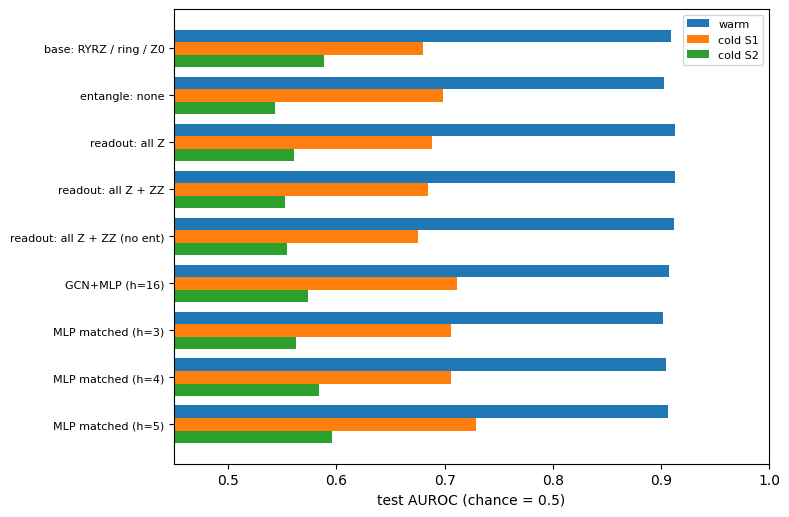

In [ ]:
import matplotlib.pyplot as plt
names = [m for m in quantum] + [m for m in res.model.unique() if m not in quantum]
w = res.pivot_table(index="model", columns="setting", values="AUROC", aggfunc="mean").reindex(names)[order_settings]
fig, ax = plt.subplots(figsize=(8, 0.42 * len(w) + 1.5)); h = 0.8 / len(order_settings)
for j, s in enumerate(order_settings):
    ax.barh([i + j * h for i in range(len(w))], w[s].values, height=h, label=s)
ax.set_yticks([i + 0.4 - h / 2 for i in range(len(w))]); ax.set_yticklabels(w.index, fontsize=8); ax.invert_yaxis()
ax.set_xlabel("test AUROC (chance = 0.5)"); ax.legend(fontsize=8); ax.set_xlim(0.45, 1.0)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/auroc_by_setting.png", dpi=150); plt.show()

## 13. Package the outputs

In [ ]:
import shutil
shutil.make_archive("finalists_outputs", "zip", ".", OUT_DIR); print("wrote finalists_outputs.zip")
try:
    from google.colab import files; files.download("finalists_outputs.zip")
except Exception:
    pass

wrote finalists_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Reading the results
- **Warm vs cold:** expect all models to score much lower on S1 and especially S2 (new drugs have no graph neighbours). The interesting question is whether any decoder degrades *less*.
- **Cold-start metrics:** use AUROC and AUPR; the F1 threshold is picked on warm validation pairs and does not transfer to new drugs.
- **S2 is small** (a few hundred test pairs), so its seed-to-seed std is large. Do not read much into S2 differences without 5 seeds.
- **Selection discipline:** the finalists were chosen on validation AUPR from a single seed. Report all finalists, not just the best-looking one.
- **Not committed to GitHub:** `drugbank_ddi.csv` (DrugBank licence).